# HW7 — GANs (concepts) & AutoEncoders on FashionMNIST

**Course:** DATA 266 · **Assignment:** Homework 7 · **Submission:** website URL (your private repo `data266-<SID4>`, tag `hw7`)

- **Part 1 (written):** GAN architecture, mode collapse, and three GAN variants.
- **Part 2 (code):** Train and evaluate two autoencoders on **FashionMNIST** — a Fully-Connected AutoEncoder (**FC-AE**) and a **Variational AutoEncoder (VAE)**.

The FC-AE and VAE are the "2 different models" the assignment refers to, so no extra hyperparameter-variant model is needed. FashionMNIST is small, so this runs in ~2–4 minutes on a GPU (and is fine on CPU).


## Section 0 — Standing Requirements

### 0.1 Personal parameters
Set `SID4` once; everything else is derived. HW7 uses fixed settings for all students, so `HP_ID` is not applied. `CLS_A`/`CLS_B` are classification-focus parameters that this assignment does not use.


In [1]:
# ============================================================
# Section 0.1 — Personal Parameters  (state in first cell)
# ============================================================
SID4 = 2708   # last four digits of SJSU student ID

SEED  = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

print(f"SID4  = {SID4}")
print(f"SEED  = {SEED}")
print(f"SLICE = {SLICE}")
print(f"HP_ID = {HP_ID}   (HW7: fixed settings -> HP_ID not applied)")
print(f"CLS_A = {CLS_A}, CLS_B = {CLS_B}   (unused in HW7)")


SID4  = 2708
SEED  = 2708
SLICE = 708
HP_ID = 2   (HW7: fixed settings -> HP_ID not applied)
CLS_A = 8, CLS_B = 9   (unused in HW7)


# Part 1 — GAN Concepts (written)

## 1.1 — Fundamental architecture of a GAN

A **Generative Adversarial Network** is a pair of neural networks trained in competition.

- **Generator `G`.** Takes a random noise vector `z` sampled from a simple prior `p(z)` (usually `N(0, I)`) and maps it to the data space, `G(z)`. Its job is to turn unstructured noise into samples that look like they came from the real data distribution `p_data`. It never sees real data directly — it only learns through the gradient signal passed back from the discriminator.
- **Discriminator `D`.** A binary classifier that takes a sample (real `x` or fake `G(z)`) and outputs `D(·) ∈ (0,1)`, the estimated probability that the sample is *real*. Its job is to tell real data apart from the generator's output.

**How they interact during training.** Training alternates between the two networks on opposite objectives — a **minimax game**:

$$\min_G \max_D \; V(D,G) = \mathbb{E}_{x\sim p_{data}}[\log D(x)] + \mathbb{E}_{z\sim p(z)}[\log(1 - D(G(z)))].$$

- **D step:** maximize `V` — push `D(x)→1` for real data and `D(G(z))→0` for fakes (standard binary cross-entropy).
- **G step:** minimize `V` — make `D(G(z))→1`, i.e. fool the discriminator. In practice the **non-saturating** form is used, maximizing `log D(G(z))` instead of minimizing `log(1−D(G(z)))`, because the latter gives vanishingly small gradients early on when the generator is poor.

The two are updated in turn: as `D` gets better at spotting fakes, `G` is forced to produce more realistic samples, and as `G` improves, `D` must sharpen its decision boundary. It is an arms race.

**Theoretical goal.** The adversarial process seeks a **Nash equilibrium** where the generator's distribution matches the data distribution, `p_g = p_data`. For a fixed `G`, the optimal discriminator is `D*(x) = p_data(x) / (p_data(x) + p_g(x))`. Substituting it back shows the generator is effectively minimizing the **Jensen–Shannon divergence** between `p_g` and `p_data`. At the global optimum `p_g = p_data`, so the discriminator is maximally confused and outputs `D(·) = 1/2` everywhere — it can no longer distinguish real from fake.


## 1.2 — Mode collapse: what it is, why it happens, and how to mitigate it

**What it is.** Mode collapse is when the generator produces only a small number of distinct outputs (or a few "modes") regardless of the input noise `z`, failing to cover the full diversity of the real data. In the extreme, many different `z` vectors all map to nearly the same image. The samples may individually look realistic, but the generator has thrown away most of the data distribution.

**Why it occurs.** The minimax objective rewards *fooling the current discriminator*, not *covering the distribution*. If the generator finds one mode that reliably fools `D`, it is locally optimal to pile all its probability mass there. The non-stationary, alternating optimization makes this worse: the generator chases whatever the current `D` is weak against, `D` then adapts to punish that mode, the generator jumps to another single mode, and the two can cycle without ever converging to full coverage. There is no explicit term in the vanilla objective that penalizes low diversity.

**Two mitigation techniques (with mechanisms):**

1. **Minibatch discrimination (and minibatch standard deviation).** The discriminator is given information about an *entire batch* of samples rather than judging each one in isolation — e.g. it computes feature-space distances between samples in the batch, or appends the per-feature standard deviation of the batch as an extra channel. **Mechanism:** a collapsed generator produces a batch of near-identical samples, which has unusually low intra-batch variation; the discriminator can now *see* that and classify such low-diversity batches as fake. This directly penalizes collapse and pushes the generator to produce varied outputs.

2. **Wasserstein GAN with gradient penalty (WGAN-GP).** Replaces the JS-divergence objective with the **Wasserstein (earth-mover) distance**, using a *critic* that outputs an unbounded real score (not a probability) constrained to be 1-Lipschitz via a gradient penalty. **Mechanism:** the Wasserstein distance provides smooth, non-vanishing gradients even when real and fake distributions barely overlap (which is exactly when a standard GAN's gradients die and collapse sets in). Because the loss correlates with how far `p_g` is from `p_data` over the *whole* support, the generator is rewarded for spreading mass to cover all modes rather than parking on one.

*(Other valid techniques include **unrolled GANs** — the generator optimizes against several look-ahead updates of the discriminator, so it cannot exploit a single `D`; **feature matching**; **PacGAN**; and **spectral normalization** for Lipschitz control.)*


## 1.3 — Three significant GAN variants

**1. DCGAN (Deep Convolutional GAN).**
- *Problem addressed:* the original GAN used fully-connected nets and was notoriously unstable and low-quality on images.
- *Innovations:* an all-convolutional architecture with a set of now-standard stabilizing choices — strided convolutions for downsampling (D) and transposed/fractionally-strided convolutions for upsampling (G) instead of pooling; **batch normalization** in both networks; removal of fully-connected hidden layers; **ReLU** in the generator (Tanh at the output) and **LeakyReLU** in the discriminator. These give stable training and learned, meaningful feature hierarchies (and interpretable latent-space arithmetic). DCGAN is the template most later image GANs build on.

**2. Conditional GAN (cGAN).**
- *Problem addressed:* a vanilla GAN generates from random noise with **no control** over *what* it produces — you cannot ask for a specific class.
- *Innovations:* both `G` and `D` are **conditioned on side information** `y` (e.g. a class label), so the generator models `G(z, y)` and the discriminator evaluates `D(x, y)` — judging not just "is this real?" but "is this a real example *of class y*?". The conditioning is typically injected by concatenating an embedding of `y` to the inputs. This enables **controllable, class-specific generation** and underlies image-to-image models like pix2pix.

**3. CycleGAN.**
- *Problem addressed:* image-to-image translation normally needs **paired** training data (the same scene in both domains), which is often impossible to collect (e.g. photo ↔ Monet painting).
- *Innovations:* learns translation between two domains from **unpaired** collections using two generators (`G: X→Y`, `F: Y→X`) and two discriminators, trained with a **cycle-consistency loss** that forces `F(G(x)) ≈ x` and `G(F(y)) ≈ y`. **Mechanism:** cycle-consistency constrains the otherwise under-determined mapping so that translating to the other domain and back returns the original, preserving content while changing style — enabling unpaired style transfer, season/object transfiguration, etc.

*(StyleGAN is another major variant: a style-based generator with a mapping network and AdaIN that injects styles at each resolution, giving disentangled, scale-specific control and state-of-the-art high-resolution faces.)*


# Part 2 — AutoEncoders on FashionMNIST (FC-AE and VAE)

### Setup — dependencies, seeds, device

In [2]:
%pip install -q torch torchvision matplotlib numpy


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: C:\Users\dipin\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [3]:
import os, random, time, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms
from torchvision.datasets import FashionMNIST
from torchvision.utils import make_grid
import matplotlib.pyplot as plt

def set_seed(seed):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Torch:", torch.__version__, "| device:", device)

# ---- Config ----
DATA_ROOT = "./data"
BATCH = 128
EPOCHS = 20
LR = 1e-3
LATENT = 32            # same latent size for FC-AE and VAE, for a fair comparison
NUM_WORKERS = 0        # FashionMNIST is tiny and in-memory; 0 avoids any Windows worker issues
CLASSES = ["T-shirt/top","Trouser","Pullover","Dress","Coat",
           "Sandal","Shirt","Sneaker","Bag","Ankle boot"]


Torch: 2.5.1+cu121 | device: cuda


In [4]:
tf = transforms.ToTensor()   # images in [0,1], shape [1,28,28]
train_ds = FashionMNIST(DATA_ROOT, train=True,  transform=tf, download=True)
test_ds  = FashionMNIST(DATA_ROOT, train=False, transform=tf, download=True)
train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=NUM_WORKERS)
test_loader  = DataLoader(test_ds,  batch_size=BATCH, shuffle=False, num_workers=NUM_WORKERS)
print(f"train: {len(train_ds)} | test: {len(test_ds)} | image shape: {train_ds[0][0].shape}")


100%|██████████| 26.4M/26.4M [00:02<00:00, 10.8MB/s]


Extracting ./data\FashionMNIST\raw\train-images-idx3-ubyte.gz to ./data\FashionMNIST\raw



100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]


Extracting ./data\FashionMNIST\raw\train-labels-idx1-ubyte.gz to ./data\FashionMNIST\raw



100%|██████████| 4.42M/4.42M [00:01<00:00, 3.63MB/s]


Extracting ./data\FashionMNIST\raw\t10k-images-idx3-ubyte.gz to ./data\FashionMNIST\raw



100%|██████████| 5.15k/5.15k [00:00<?, ?B/s]

Extracting ./data\FashionMNIST\raw\t10k-labels-idx1-ubyte.gz to ./data\FashionMNIST\raw

train: 60000 | test: 10000 | image shape: torch.Size([1, 28, 28])


## Part 2a — Fully-Connected AutoEncoder (FC-AE)

A symmetric MLP autoencoder: the encoder compresses the flattened 784-pixel image down to a `LATENT`-dim code, and the decoder reconstructs it. Trained to minimize **binary cross-entropy** reconstruction loss (pixels are in [0,1]).

In [5]:
class FCAE(nn.Module):
    def __init__(self, latent=LATENT):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256), nn.ReLU(True),
            nn.Linear(256, 128), nn.ReLU(True),
            nn.Linear(128, latent),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent, 128), nn.ReLU(True),
            nn.Linear(128, 256), nn.ReLU(True),
            nn.Linear(256, 784), nn.Sigmoid(),
        )
    def forward(self, x):
        z = self.encoder(x.view(x.size(0), -1))
        return self.decoder(z).view(x.size(0), 1, 28, 28), z

def train_fcae():
    set_seed(SEED)
    model = FCAE().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    for ep in range(EPOCHS):
        model.train(); running = 0.0
        for x, _ in train_loader:
            x = x.to(device)
            recon, _ = model(x)
            loss = F.binary_cross_entropy(recon, x, reduction="sum") / x.size(0)
            opt.zero_grad(); loss.backward(); opt.step()
            running += loss.item() * x.size(0)
        print(f"[fc-ae] epoch {ep:2d}  train BCE/img {running/len(train_ds):.3f}")
    return model

t0 = time.time()
fcae = train_fcae()
print(f"FC-AE trained in {time.time()-t0:.0f}s")
torch.save(fcae.state_dict(), "hw7_fcae.pt")


[fc-ae] epoch  0  train BCE/img 274.014
[fc-ae] epoch  1  train BCE/img 236.513
[fc-ae] epoch  2  train BCE/img 230.559
[fc-ae] epoch  3  train BCE/img 227.152
[fc-ae] epoch  4  train BCE/img 224.777
[fc-ae] epoch  5  train BCE/img 222.756
[fc-ae] epoch  6  train BCE/img 221.137
[fc-ae] epoch  7  train BCE/img 219.894
[fc-ae] epoch  8  train BCE/img 218.766
[fc-ae] epoch  9  train BCE/img 217.883
[fc-ae] epoch 10  train BCE/img 217.087
[fc-ae] epoch 11  train BCE/img 216.305
[fc-ae] epoch 12  train BCE/img 215.671
[fc-ae] epoch 13  train BCE/img 215.139
[fc-ae] epoch 14  train BCE/img 214.614
[fc-ae] epoch 15  train BCE/img 214.143
[fc-ae] epoch 16  train BCE/img 213.724
[fc-ae] epoch 17  train BCE/img 213.352
[fc-ae] epoch 18  train BCE/img 213.004
[fc-ae] epoch 19  train BCE/img 212.649
FC-AE trained in 77s


## Part 2b — Variational AutoEncoder (VAE)

The encoder outputs a mean `μ` and log-variance `logσ²` for a `LATENT`-dim Gaussian; a latent `z` is drawn with the **reparameterization trick** `z = μ + σ·ε` (`ε ~ N(0,I)`) so gradients flow. The loss is **reconstruction BCE + KL divergence** to the standard-normal prior — the KL term regularizes the latent space so it can be sampled for generation.

In [6]:
class VAE(nn.Module):
    def __init__(self, latent=LATENT):
        super().__init__()
        self.fc1  = nn.Linear(784, 400)
        self.fc_mu     = nn.Linear(400, latent)
        self.fc_logvar = nn.Linear(400, latent)
        self.fc2  = nn.Linear(latent, 400)
        self.fc3  = nn.Linear(400, 784)
    def encode(self, x):
        h = F.relu(self.fc1(x.view(x.size(0), -1)))
        return self.fc_mu(h), self.fc_logvar(h)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + std * torch.randn_like(std)
    def decode(self, z):
        return torch.sigmoid(self.fc3(F.relu(self.fc2(z))))
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z).view(x.size(0), 1, 28, 28)
        return recon, mu, logvar

def vae_loss(recon, x, mu, logvar):
    bce = F.binary_cross_entropy(recon, x, reduction="sum") / x.size(0)
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / x.size(0)
    return bce + kld, bce, kld

def train_vae():
    set_seed(SEED)
    model = VAE().to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    for ep in range(EPOCHS):
        model.train(); rl = rb = rk = 0.0
        for x, _ in train_loader:
            x = x.to(device)
            recon, mu, logvar = model(x)
            loss, bce, kld = vae_loss(recon, x, mu, logvar)
            opt.zero_grad(); loss.backward(); opt.step()
            n = x.size(0)
            rl += loss.item()*n; rb += bce.item()*n; rk += kld.item()*n
        N = len(train_ds)
        print(f"[vae] epoch {ep:2d}  ELBO/img {rl/N:.3f}  (BCE {rb/N:.3f} + KL {rk/N:.3f})")
    return model

t0 = time.time()
vae = train_vae()
print(f"VAE trained in {time.time()-t0:.0f}s")
torch.save(vae.state_dict(), "hw7_vae.pt")


[vae] epoch  0  ELBO/img 288.514  (BCE 273.511 + KL 15.004)
[vae] epoch  1  ELBO/img 258.777  (BCE 243.102 + KL 15.675)
[vae] epoch  2  ELBO/img 251.910  (BCE 236.494 + KL 15.416)
[vae] epoch  3  ELBO/img 248.581  (BCE 233.136 + KL 15.446)
[vae] epoch  4  ELBO/img 246.637  (BCE 231.103 + KL 15.535)
[vae] epoch  5  ELBO/img 245.383  (BCE 229.693 + KL 15.690)
[vae] epoch  6  ELBO/img 244.518  (BCE 228.713 + KL 15.804)
[vae] epoch  7  ELBO/img 243.809  (BCE 227.926 + KL 15.883)
[vae] epoch  8  ELBO/img 243.243  (BCE 227.302 + KL 15.941)
[vae] epoch  9  ELBO/img 242.862  (BCE 226.879 + KL 15.983)
[vae] epoch 10  ELBO/img 242.413  (BCE 226.402 + KL 16.011)
[vae] epoch 11  ELBO/img 242.098  (BCE 226.034 + KL 16.064)
[vae] epoch 12  ELBO/img 241.779  (BCE 225.696 + KL 16.083)
[vae] epoch 13  ELBO/img 241.490  (BCE 225.400 + KL 16.090)
[vae] epoch 14  ELBO/img 241.274  (BCE 225.143 + KL 16.131)
[vae] epoch 15  ELBO/img 241.064  (BCE 224.920 + KL 16.144)
[vae] epoch 16  ELBO/img 240.865  (BCE 2

## Part 2c — Evaluation

We evaluate both models on the **test set** with a common, comparable metric (per-pixel MSE and BCE on reconstructions), then show reconstructions side by side and sample new images from the VAE's prior.

In [7]:
@torch.no_grad()
def eval_reconstruction(model, is_vae):
    model.eval(); mse = bce = n = 0
    for x, _ in test_loader:
        x = x.to(device)
        if is_vae:
            mu, logvar = model.encode(x)
            recon = model.decode(mu).view_as(x)   # use the mean (deterministic) for eval
        else:
            recon, _ = model(x)
        mse += F.mse_loss(recon, x, reduction="sum").item()
        bce += F.binary_cross_entropy(recon, x, reduction="sum").item()
        n += x.numel()
    return mse / n, bce / n     # per-pixel

fcae_mse, fcae_bce = eval_reconstruction(fcae, is_vae=False)
vae_mse,  vae_bce  = eval_reconstruction(vae,  is_vae=True)
print(f"{'model':<8}{'test MSE/px':>14}{'test BCE/px':>14}")
print(f"{'FC-AE':<8}{fcae_mse:>14.5f}{fcae_bce:>14.5f}")
print(f"{'VAE':<8}{vae_mse:>14.5f}{vae_bce:>14.5f}")


model      test MSE/px   test BCE/px
FC-AE          0.01005       0.27364
VAE            0.01282       0.28183


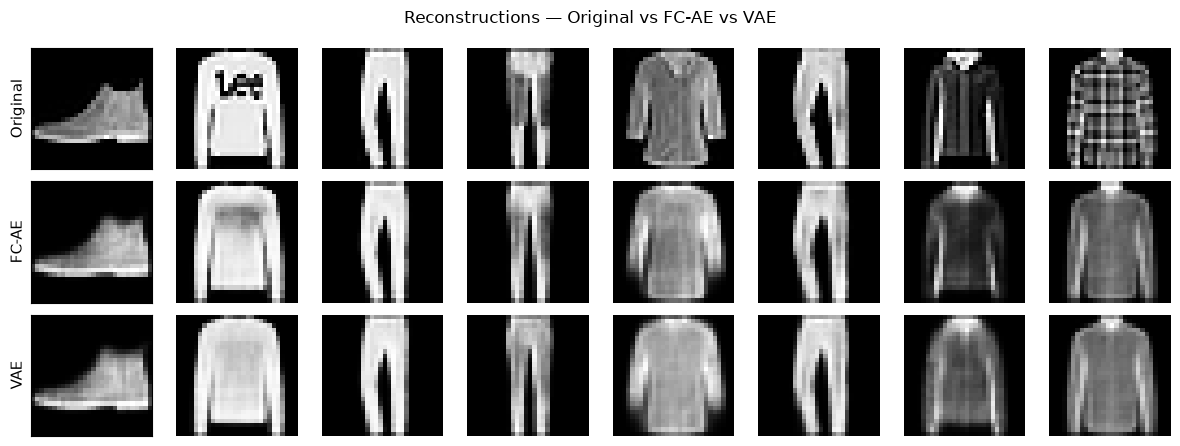

Saved -> hw7_reconstructions.png


In [8]:
# Reconstructions: original vs FC-AE vs VAE on the same 8 test images
set_seed(SEED)
x, _ = next(iter(test_loader))
x8 = x[:8].to(device)
with torch.no_grad():
    fc_rec, _ = fcae(x8)
    mu, logvar = vae.encode(x8); vae_rec = vae.decode(mu).view_as(x8)

rows = [("Original", x8), ("FC-AE", fc_rec), ("VAE", vae_rec)]
fig, axes = plt.subplots(3, 8, figsize=(12, 4.5))
for r, (name, imgs) in enumerate(rows):
    for c in range(8):
        axes[r][c].imshow(imgs[c].cpu().squeeze(), cmap="gray")
        axes[r][c].axis("off")
    axes[r][0].set_ylabel(name, fontsize=11, rotation=90)
    axes[r][0].axis("on"); axes[r][0].set_xticks([]); axes[r][0].set_yticks([])
fig.suptitle("Reconstructions — Original vs FC-AE vs VAE")
fig.tight_layout(); fig.savefig("hw7_reconstructions.png", dpi=120, bbox_inches="tight"); plt.show()
print("Saved -> hw7_reconstructions.png")


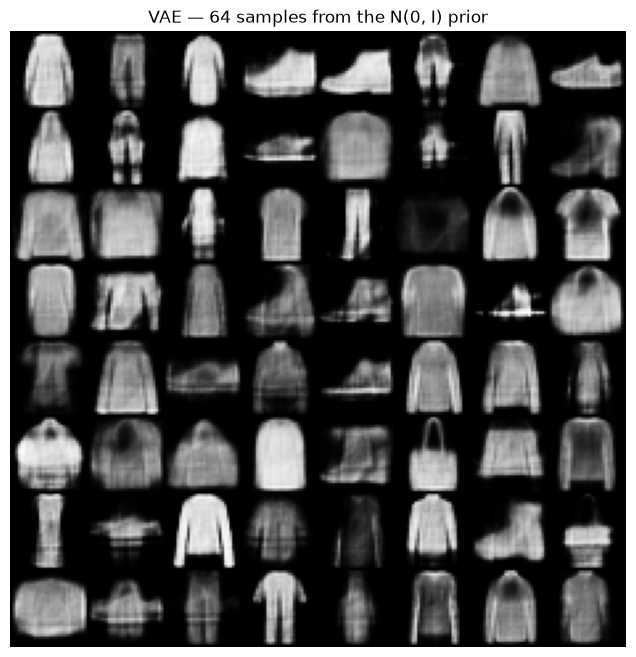

Saved -> hw7_vae_samples.png


In [9]:
# VAE generation: sample z ~ N(0, I) and decode (FC-AE cannot do this meaningfully)
set_seed(SEED)
with torch.no_grad():
    z = torch.randn(64, LATENT, device=device)
    samples = vae.decode(z).view(64, 1, 28, 28).cpu()
grid = make_grid(samples, nrow=8, padding=1)
plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray"); plt.axis("off")
plt.title("VAE — 64 samples from the N(0, I) prior")
plt.savefig("hw7_vae_samples.png", dpi=120, bbox_inches="tight"); plt.show()
print("Saved -> hw7_vae_samples.png")


### Standing artifacts (Req. 0.3) — write `METRICS.md`

In [10]:
metrics = {
    "SID4": SID4, "SEED": SEED,
    "dataset": "FashionMNIST", "latent_dim": LATENT,
    "epochs": EPOCHS, "batch": BATCH, "lr": LR,
    "test_reconstruction": {
        "FC_AE": {"mse_per_px": round(fcae_mse, 5), "bce_per_px": round(fcae_bce, 5)},
        "VAE":   {"mse_per_px": round(vae_mse, 5),  "bce_per_px": round(vae_bce, 5)},
    },
}
with open("metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=2)

lines = [
    "# METRICS - HW7 AutoEncoders on FashionMNIST\n",
    f"- SID4={SID4}, SEED={SEED}",
    f"- Dataset: FashionMNIST | latent_dim={LATENT} | epochs={EPOCHS}, batch={BATCH}, lr={LR}\n",
    "## Test-set reconstruction (lower is better)\n",
    "| model | MSE / pixel | BCE / pixel |",
    "|---|---|---|",
    f"| FC-AE | {fcae_mse:.5f} | {fcae_bce:.5f} |",
    f"| VAE | {vae_mse:.5f} | {vae_bce:.5f} |",
    "\nFC-AE optimizes reconstruction only; the VAE trades a little reconstruction accuracy",
    "for a regularized latent space it can **generate** from (see hw7_vae_samples.png).",
]
with open("METRICS.md", "w", encoding="utf-8") as f:
    f.write("\n".join(lines) + "\n")
print("\n".join(lines))
print("\nSaved -> METRICS.md, metrics.json")


# METRICS - HW7 AutoEncoders on FashionMNIST

- SID4=2708, SEED=2708
- Dataset: FashionMNIST | latent_dim=32 | epochs=20, batch=128, lr=0.001

## Test-set reconstruction (lower is better)

| model | MSE / pixel | BCE / pixel |
|---|---|---|
| FC-AE | 0.01005 | 0.27364 |
| VAE | 0.01282 | 0.28183 |

FC-AE optimizes reconstruction only; the VAE trades a little reconstruction accuracy
for a regularized latent space it can **generate** from (see hw7_vae_samples.png).

Saved -> METRICS.md, metrics.json


## Comparison & Discussion

**Reconstruction quality.** On the 10,000-image test set the **FC-AE reached the lower reconstruction error — MSE/px 0.01005 vs the VAE's 0.01282 (≈22% lower), and BCE/px 0.27364 vs 0.28183.** This is expected: the FC-AE's entire objective is to copy the input through its 32-dim bottleneck, with nothing competing against reconstruction. The VAE's loss adds a **KL term** (its final training ELBO was 240.4/img = BCE 224.2 + KL 16.2) that pulls each image's latent distribution toward `N(0, I)`, sacrificing a little pixel accuracy for a regular latent space. In the reconstruction figure both reproduce garments faithfully, but the VAE's are slightly **softer/blurrier** — the visible signature of the KL regularization.

**What the VAE buys with that trade-off.** The KL term organizes the latent space into a smooth, continuous region matching the prior, so sampling **`z ~ N(0, I)` and decoding produces new, plausible FashionMNIST-like images** (hw7_vae_samples.png). The FC-AE has no such constraint — its latent codes occupy an irregular, hole-filled region, so decoding random latents yields noise rather than clothing. In short: **FC-AE = better reconstruction, no real generation; VAE = slightly worse reconstruction, but a usable generative model.** The ~22% MSE gap is the concrete cost of making the latent space sampleable, and for FashionMNIST it's a small price for a model that can actually generate.

## Files produced

| File | For |
|---|---|
| `hw7_fcae.pt`, `hw7_vae.pt` | trained model checkpoints |
| `hw7_reconstructions.png` | original vs FC-AE vs VAE reconstructions |
| `hw7_vae_samples.png` | VAE samples from the prior |
| `METRICS.md`, `metrics.json` | Req. 0.3 metrics |

**Repo checklist (Req. 0.3):** executed `.ipynb` (Part 1 written answers + Part 2 code), `METRICS.md`, `RUN_LOG.txt`, `AI_USE.md`, and the two checkpoints in your private repo `data266-<SID4>`, tagged **`hw7`**. Commit **incrementally**.
